In [1]:
import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler



In [154]:
def load_images_from_folder(dataset_path, image_size=(100, 100)):
    X = []
    y = []
    labels = os.listdir(dataset_path)
    
    for label in labels:
        person_folder = os.path.join(dataset_path, label)
        if not os.path.isdir(person_folder):
            continue
        for filename in os.listdir(person_folder):
            img_path = os.path.join(person_folder, filename)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, image_size)
                X.append(img.flatten())
                y.append(label)
    

    return np.array(X), np.array(y)


In [148]:
dataset_path = "C:/Users/hp/Downloads/dataset/dataset/faces/"
  # Replace with your actual dataset path
X, y = load_images_from_folder(dataset_path)
print("Dataset loaded. Total samples:", len(X))


Dataset loaded. Total samples: 450


In [149]:

# Normalize the pixel values to be between 0 and 1
X = X / 255.0

In [155]:
# Encode labels to integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_test_original = X_test.copy()



In [156]:
# Apply PCA for dimensionality reduction
pca = PCA(n_components=0.95)  # Retain 95% of variance
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Scale the data
scaler = StandardScaler()
X_train_pca = scaler.fit_transform(X_train_pca)
X_test_pca = scaler.transform(X_test_pca)


In [172]:
# Initialize and train the MLP Classifier
mlp = MLPClassifier(hidden_layer_sizes=(374,353), max_iter=1000, activation='relu', solver='adam', random_state=42)
mlp.fit(X_train_pca, y_train)

# Evaluate the model on the test data
y_pred = mlp.predict(X_test_pca)

# Print accuracy and classification report
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Accuracy: 80.00%

Classification Report:
               precision    recall  f1-score   support

       Aamir       0.90      0.75      0.82        12
        Ajay       0.83      0.71      0.77        14
      Akshay       1.00      0.89      0.94         9
        Alia       0.60      0.86      0.71         7
     Amitabh       1.00      1.00      1.00         8
     Deepika       0.62      0.62      0.62         8
       Disha       0.56      0.83      0.67         6
      Farhan       0.87      0.93      0.90        14
      Ileana       0.80      0.67      0.73        12

    accuracy                           0.80        90
   macro avg       0.80      0.81      0.79        90
weighted avg       0.82      0.80      0.80        90



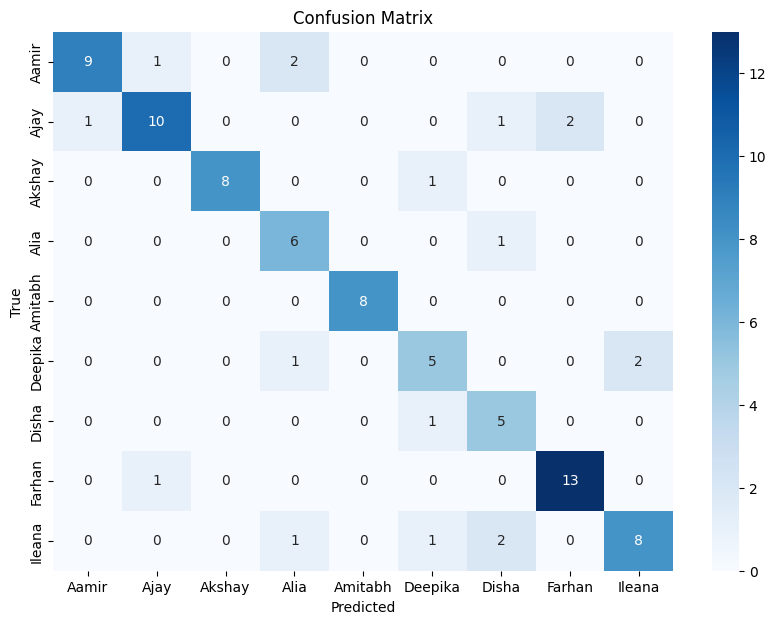

In [158]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [159]:

from sklearn.neighbors import KNeighborsClassifier
k_values = list(range(1, 21))
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"K={k}: Accuracy = {acc * 100:.2f}%")

K=1: Accuracy = 50.00%
K=2: Accuracy = 50.00%
K=3: Accuracy = 41.11%
K=4: Accuracy = 38.89%
K=5: Accuracy = 36.67%
K=6: Accuracy = 35.56%
K=7: Accuracy = 34.44%
K=8: Accuracy = 31.11%
K=9: Accuracy = 27.78%
K=10: Accuracy = 26.67%
K=11: Accuracy = 25.56%
K=12: Accuracy = 20.00%
K=13: Accuracy = 21.11%
K=14: Accuracy = 24.44%
K=15: Accuracy = 21.11%
K=16: Accuracy = 21.11%
K=17: Accuracy = 22.22%
K=18: Accuracy = 22.22%
K=19: Accuracy = 18.89%
K=20: Accuracy = 15.56%


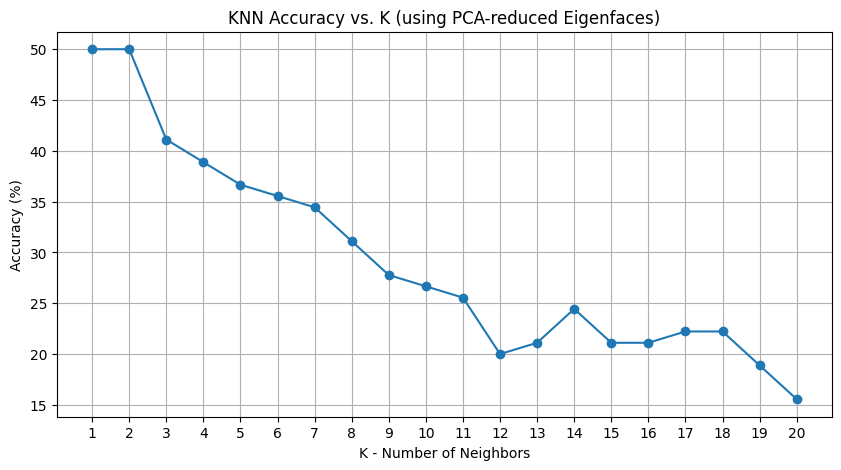

In [160]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(k_values, [a * 100 for a in accuracies], marker='o')
plt.title('KNN Accuracy vs. K (using PCA-reduced Eigenfaces)')
plt.xlabel('K - Number of Neighbors')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.xticks(k_values)
plt.show()

 Correct predictions: 72
 Incorrect predictions: 18


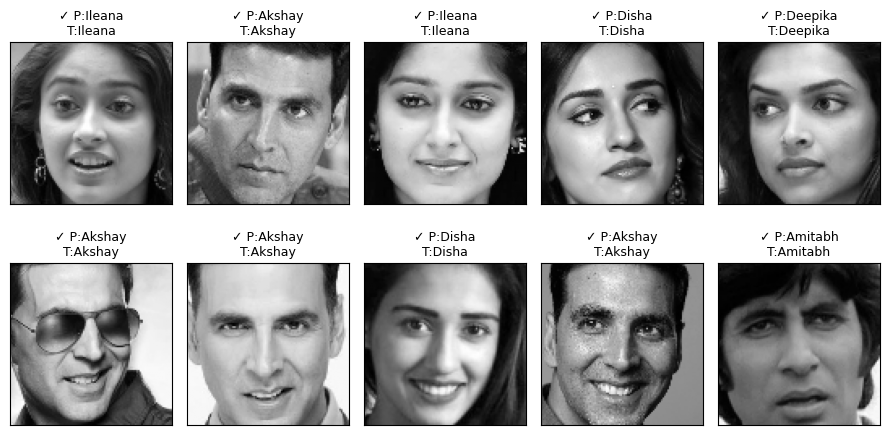

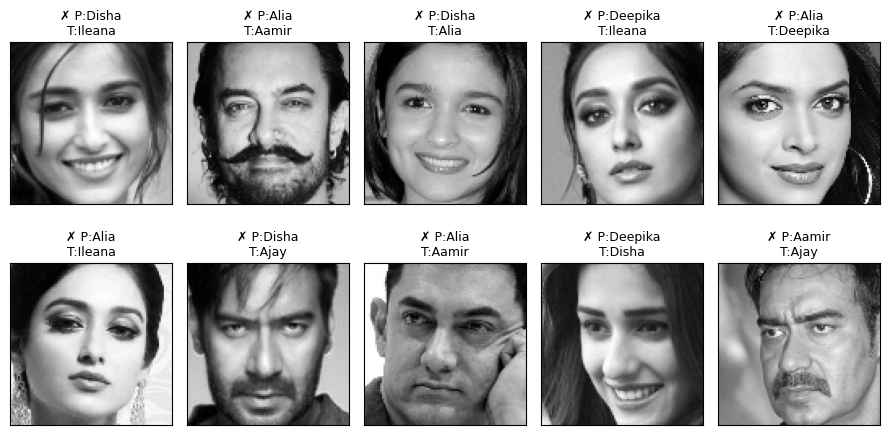

In [174]:
import numpy as np
import matplotlib.pyplot as plt

# Define face plotting function
def plot_faces(images, titles, h, w, rows=2, cols=5):
    plt.figure(figsize=(1.8 * cols, 2.4 * rows))
    for i in range(min(rows * cols, len(images))):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap='gray')
        plt.title(titles[i], size=9)
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()

# Set image shape
h, w = 100, 100  # or 64, 64 based on your input

# Find correct and incorrect indices
correct_idx = np.where(y_pred == y_test)[0]
incorrect_idx = np.where(y_pred != y_test)[0]

print(f" Correct predictions: {len(correct_idx)}")
print(f" Incorrect predictions: {len(incorrect_idx)}")

# Titles
correct_titles = [f"✓ P:{label_encoder.inverse_transform([y_pred[i]])[0]}\nT:{label_encoder.inverse_transform([y_test[i]])[0]}" for i in correct_idx[:10]]
incorrect_titles = [f"✗ P:{label_encoder.inverse_transform([y_pred[i]])[0]}\nT:{label_encoder.inverse_transform([y_test[i]])[0]}" for i in incorrect_idx[:10]]

# Show face images (use original flattened grayscale images)
plot_faces(X_test[correct_idx[:10]], correct_titles, h, w)
plot_faces(X_test[incorrect_idx[:10]], incorrect_titles, h, w)
